# Extract and fit G values curves 


From: https://www.mdpi.com/1422-0067/21/2/424  
=> Impact of Target Oxygenation on the Chemical Track Evolution of Ion and Electron Radiation

In [176]:
import pandas as pd
from numpy.polynomial import Polynomial
from typing import Dict
import numpy as np
import re
from more_itertools import grouper
from pathlib import Path
data_dir = Path(r"C:\Users\rtonneau\DEV\PYTHON\radiopyo_vec\radiopyo_vec\data\G_VALUES")

In [121]:
from lmfit.models import PolynomialModel, SplineModel

In [95]:
from Plot_template import RPlot, FigManager
FM = FigManager()
RPlot.init_rcparams()

## Import data as DataFrame

In [171]:
def extract_from_csv(file: Path) -> Dict[str,pd.Series]:
    out = dict()
    if not file.exists():
        raise FileNotFoundError(file)
    df = pd.read_csv(file).drop(0, axis=0)
    for col_x, col_y in grouper(df.columns, 2):
        out[col_x] = pd.Series(data=df[col_y].values, index=df[col_x].values.astype(np.float64), dtype=np.float64).dropna().clip(lower=0.0,)
    return out

def parse_labels_and_sort(data:Dict[str,pd.Series]) -> Dict[str, pd.DataFrame]:
    regex = re.compile(r"(?P<species>.*)__pO2__(?P<O2>\d+_?\d?)")
    species = dict()
    for key in data:
        res = regex.match(key)
        l = species.get(res.group("species"), [])
        species[res.group("species")] = l + [res]

    x_eval = np.linspace(0.5, 150, 100)
    out = {sp:pd.DataFrame(index=x_eval) for sp in species}
    for key, values in species.items():
        for elt in values:
            serie = data[elt.string]
            model = SplineModel(xknots=serie.index.values)
            params = model.guess(serie.values, serie.index.values)
            res = model.fit(serie.values, params, x=serie.index.values)
            out[key][float(elt.group("O2").replace("_","."))] = res.eval(x=x_eval)
    return out

In [177]:
res = extract_from_csv(data_dir/"H2.csv")
res = parse_labels_and_sort(res)

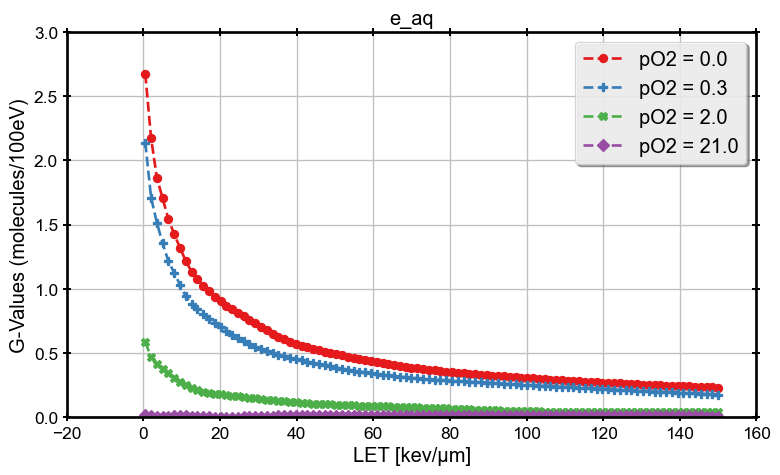

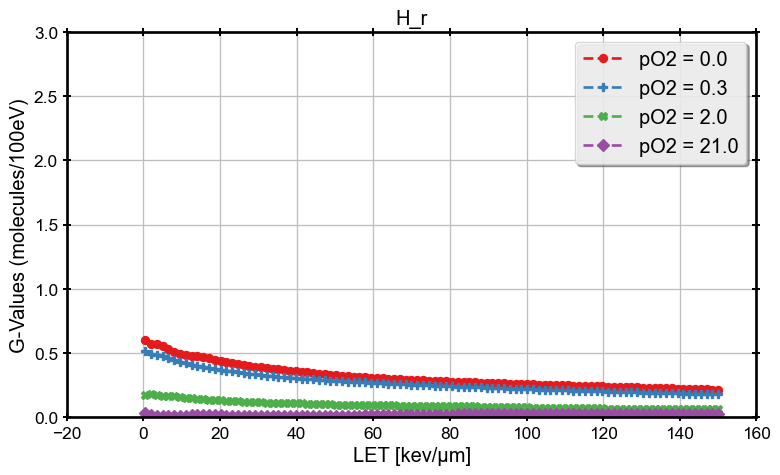

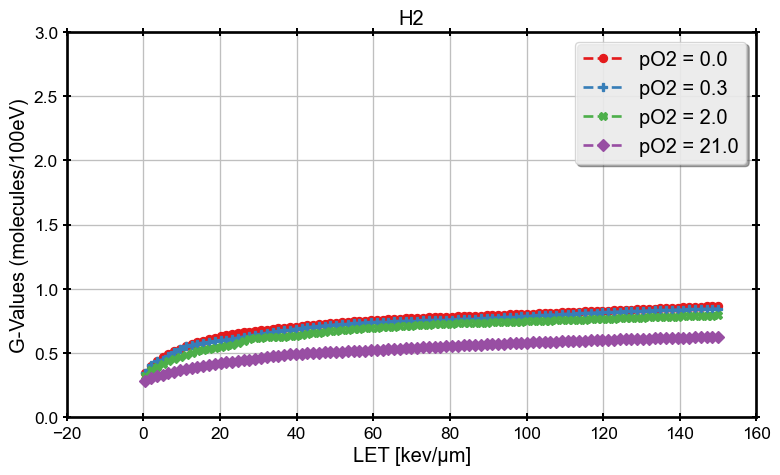

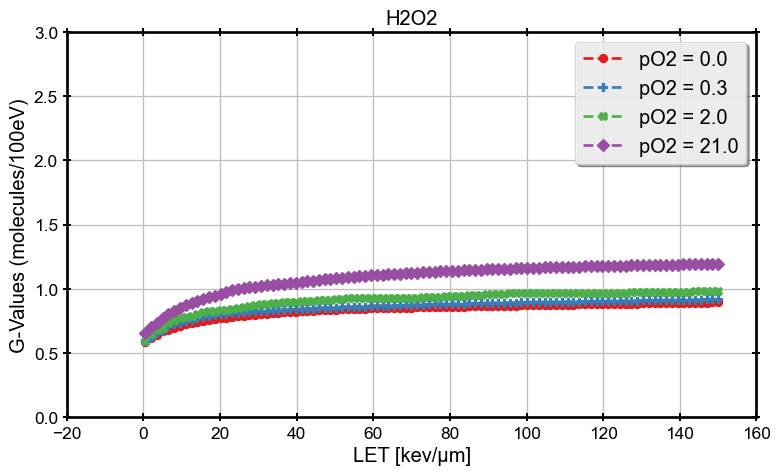

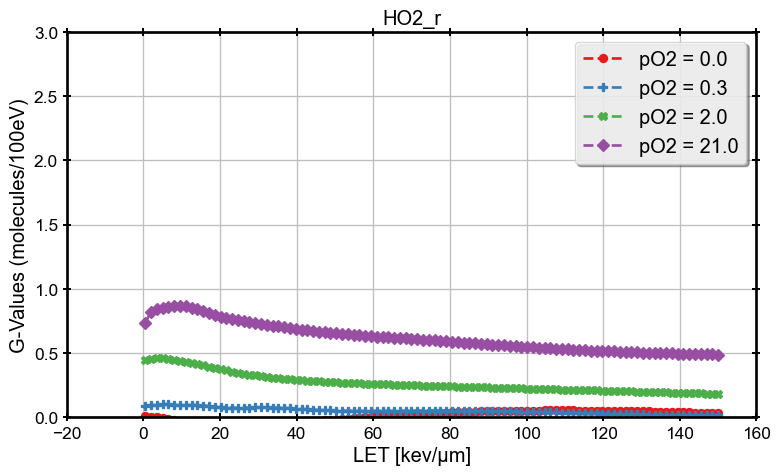

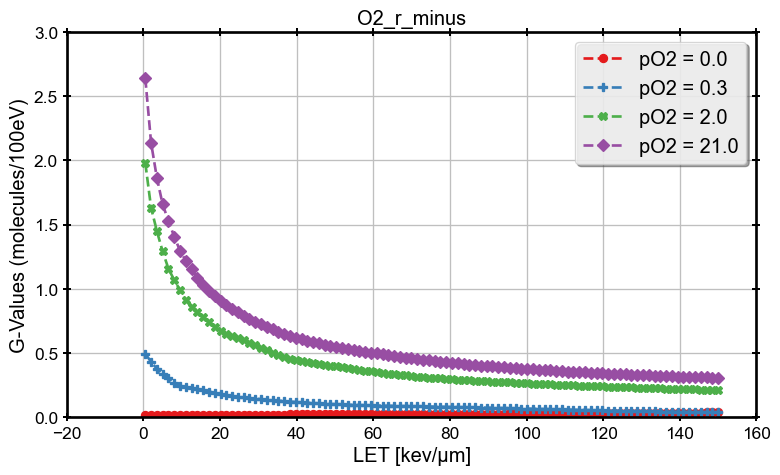

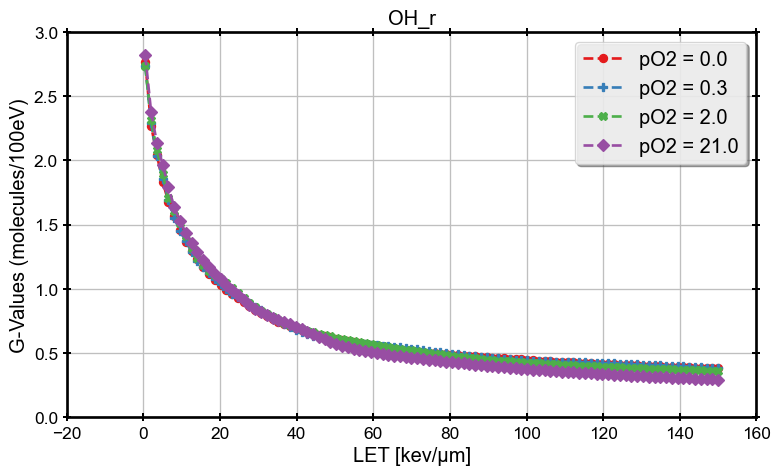

In [178]:
for species in res:
    with FM.open(f"Fit {species}") as (fig, ax):
        for col in res[species]:
            ax.plot(res[species][col].index, res[species][col].values, label=f"pO2 = {col}")
        ax.legend()
        ax.set_title(species)
        ax.set_ylim([0,3])
        #ax.set_xlim([0.1,1e3])
        ax.set_ylabel("G-Values (molecules/100eV)", fontsize=15)
        ax.set_xlabel("LET [kev/µm]", fontsize=15)

In [182]:
res["e_aq"][21]

0.500000      0.017665
2.010101      0.013720
3.520202      0.004219
5.030303      0.001995
6.540404      0.004394
                ...   
143.959596    0.007246
145.469697    0.007007
146.979798    0.006766
148.489899    0.006523
150.000000    0.006278
Name: 21.0, Length: 100, dtype: float64

In [185]:
desired = ["e_aq", "H_r", "OH_r", "H2", "H2O2"]
out = pd.DataFrame()
for species in desired:
    df = res[species]
    out[species] = df[0]
out

,e_aq,H_r,OH_r,H2,H2O2
0.500000,2.675317,0.598752,2.765497,0.345189,0.589781
2.010101,2.175131,0.574461,2.271000,0.403404,0.619621
3.520202,1.865436,0.570280,2.045107,0.441762,0.640657
5.030303,1.704470,0.557810,1.835217,0.471161,0.670011
6.540404,1.541993,0.533481,1.678460,0.495400,0.681691
...,...,...,...,...,...
143.959596,0.238898,0.220494,0.386806,0.860164,0.892536
145.469697,0.237231,0.219325,0.385262,0.861999,0.893102
146.979798,0.235596,0.218168,0.383751,0.863821,0.893659
148.489899,0.233991,0.217023,0.382270,0.865631,0.894209


In [186]:
out.to_csv(r"C:\Users\rtonneau\DEV\PYTHON\radiopyo_vec\radiopyo_vec\data\G_VALUES\gvalues_from_Boscolo_2020.csv")